# Visão Computacional para Manutenção Urbana: detecção de fissuras em concreto
Global Solution 2026.2, turma 2TIA (CitizenTech)

Este notebook cobre os itens 1, 2, 3 e 5 da atividade e gera o vídeo do item 4:

1. Seleção e preparação dos dados (Concrete Crack Images for Classification)
2. Implementação: transferência de aprendizado com MobileNetV2 (comparada com ResNet18)
3. Avaliação: precisão, recall, F1, matriz de confusão, análise de acertos, erros e interferências
4. Processamento de vídeo / sequência de imagens (simulação de monitoramento)
5. Latência por imagem, FPS e justificativa da arquitetura e do limiar

> A integração com o protótipo fica em `app/app.py` (Streamlit), que usa o mesmo módulo `src/detector.py`.

In [1]:
import sys, json, time, platform, random
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))

import numpy as np, pandas as pd, matplotlib.pyplot as plt, cv2, torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import transforms
from PIL import Image
from sklearn.metrics import (precision_score, recall_score, f1_score, accuracy_score,
                             confusion_matrix, ConfusionMatrixDisplay, roc_auc_score,
                             precision_recall_curve, classification_report)

from detector import build_model, eval_transform, MEAN, STD, IMG_SIZE, CrackDetector
from dataset import CrackDataset, PERTURBACOES, aumento_campo

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DATA = ROOT / 'data'; OUT = ROOT / 'outputs'; MODELS = ROOT / 'models'
OUT.mkdir(exist_ok=True); MODELS.mkdir(exist_ok=True)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
# fp16 deu NaN na ResNet18 nesta GPU
USE_AMP = False
GPU = torch.cuda.get_device_name(0) if device.type == 'cuda' else 'sem GPU'
print('Python', platform.python_version(), '| torch', torch.__version__, '| dispositivo:', device, '-', GPU)
print('CPU:', platform.processor())

Python 3.13.14 | torch 2.14.1+cu126 | dispositivo: cuda - NVIDIA GeForce GTX 1660 SUPER
CPU: Intel64 Family 6 Model 165 Stepping 5, GenuineIntel


## 1. Seleção e preparação dos dados

**Base escolhida:** *Concrete Crack Images for Classification* (Özgenel, 2018, Mendeley Data, DOI 10.17632/5y9wdsg2zt.2).
São 40 mil recortes RGB de 227×227 px de paredes de concreto, 20 mil com fissura (`Positive`) e 20 mil sem (`Negative`),
gerados a partir de 458 fotos de alta resolução de prédios do campus da METU. É a base indicada no enunciado para o prazo de quatro horas.

Negative: 20000 imagens
Positive: 20000 imagens
Tamanho / modo: (227, 227) RGB


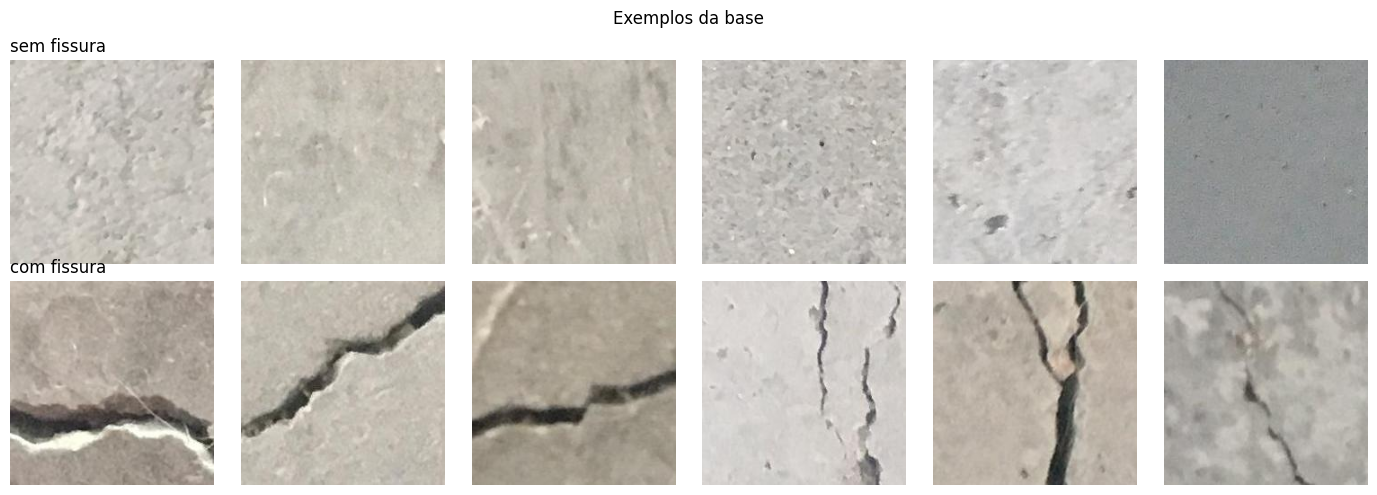

In [2]:
classes = {'Negative': 0, 'Positive': 1}
arquivos = {c: sorted((DATA / c).glob('*.jpg')) for c in classes}
for c, fs in arquivos.items():
    print(f'{c}: {len(fs)} imagens')
amostra = [Image.open(f) for f in arquivos['Positive'][:3]]
print('Tamanho / modo:', amostra[0].size, amostra[0].mode)

fig, axes = plt.subplots(2, 6, figsize=(14, 5))
for row, c in enumerate(classes):
    for ax, f in zip(axes[row], random.sample(arquivos[c], 6)):
        ax.imshow(Image.open(f)); ax.axis('off')
    axes[row][0].set_title('com fissura' if c == 'Positive' else 'sem fissura', loc='left')
plt.suptitle('Exemplos da base'); plt.tight_layout(); plt.savefig(OUT / 'exemplos_base.png', dpi=110); plt.show()

### Divisão sem vazamento entre conjuntos

O enunciado pede para não distribuir recortes da mesma imagem original entre conjuntos diferentes.
A base não informa de qual foto original veio cada recorte, mas os recortes foram gerados em sequência
(≈ 44 recortes por foto em média: 20 000 / 458). Por isso os arquivos são agrupados em **blocos de 100
arquivos consecutivos** e a divisão treino/validação/teste é feita **por bloco**. Assim, recortes vizinhos
(que tendem a vir da mesma foto) ficam sempre no mesmo conjunto. Só pode haver mistura na fronteira entre
dois blocos, o que atinge no máximo uma foto por fronteira.

Para caber no prazo, usamos uma **amostra de 60 blocos por classe (6 000 imagens por classe, 12 000 no total)**,
dividida em 70% / 15% / 15% dos blocos.

In [3]:
BLOCO = 100
linhas = []
for c, y in classes.items():
    for i, f in enumerate(arquivos[c]):
        linhas.append({'arquivo': str(f), 'classe': c, 'rotulo': y, 'grupo': f'{c}_{i // BLOCO:03d}'})
df = pd.DataFrame(linhas)

rng = np.random.default_rng(SEED)
partes = []
for c in classes:
    grupos = df.loc[df.classe == c, 'grupo'].unique()
    escolhidos = rng.choice(grupos, size=60, replace=False)
    rng.shuffle(escolhidos)
    n_tr, n_va = 42, 9
    mapa = {g: 'treino' for g in escolhidos[:n_tr]}
    mapa.update({g: 'validacao' for g in escolhidos[n_tr:n_tr + n_va]})
    mapa.update({g: 'teste' for g in escolhidos[n_tr + n_va:]})
    sub = df[df.grupo.isin(escolhidos)].copy(); sub['conjunto'] = sub.grupo.map(mapa)
    partes.append(sub)
split = pd.concat(partes, ignore_index=True)
split.to_csv(OUT / 'divisao_conjuntos.csv', index=False)

assert split.groupby('grupo').conjunto.nunique().max() == 1
print(pd.crosstab(split.conjunto, split.classe, margins=True))

classe     Negative  Positive    All
conjunto                            
teste           900       900   1800
treino         4200      4200   8400
validacao       900       900   1800
All            6000      6000  12000


### Pré-processamento

* **Redimensionamento** de 227×227 para 224×224 (entrada padrão das redes pré-treinadas na ImageNet).
* **Normalização** com média e desvio da ImageNet, para casar com os pesos pré-treinados.
* **Aumento de dados só no treino:** espelhamento horizontal/vertical, rotação de 90° e variação de brilho/contraste.
  Fissura não tem orientação fixa, e a variação de luz prepara o modelo para fotos de campo.

In [4]:
train_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(), transforms.RandomVerticalFlip(),
    transforms.RandomApply([transforms.RandomRotation((90, 90))], p=0.5),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.1),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD),
])
test_tf = eval_transform()

def loader(conjunto, tf, shuffle=False, perturb=None, bs=64, seed=SEED):
    s = split[split.conjunto == conjunto]
    ds = CrackDataset(s.arquivo, s.rotulo, tf, perturb=perturb, seed=seed)
    return DataLoader(ds, batch_size=bs, shuffle=shuffle, num_workers=2,
                      pin_memory=True, persistent_workers=False)

dl_tr, dl_va, dl_te = loader('treino', train_tf, True), loader('validacao', test_tf), loader('teste', test_tf)
dl_tr_campo = loader('treino', train_tf, True, perturb=aumento_campo, seed=None)
print(len(dl_tr.dataset), len(dl_va.dataset), len(dl_te.dataset))

8400 1800 1800


## 2. Implementação: transferência de aprendizado

**Modelo principal: MobileNetV2** pré-treinada na ImageNet, com a camada final trocada para 2 classes e
ajuste fino da rede inteira com taxa de aprendizado baixa. A MobileNetV2 usa convoluções separáveis em
profundidade (*depthwise separable*) e tem ~2,2 milhões de parâmetros, o que a torna rápida em GPU modesta,
em CPU e em celular, que é o cenário de uma prefeitura.

**Comparação: ResNet18** (~11 milhões de parâmetros), uma CNN clássica um pouco maior, para ver se a qualidade
melhora o bastante para compensar a perda de velocidade.

**Variante robusta: MobileNetV2 + aumento de campo.** Mesma rede, mas no treino metade das imagens recebe uma
condição de campo sorteada (ruído de sensor, sombra ou variação forte de luz, com intensidade aleatória).
Motivo: a MobileNetV2 treinada só com a base limpa perde fissuras com ruído e dá alarmes falsos com sombra
(ver seção de interferências). Os riscos/manchas e os obstáculos **não** entram nesse
aumento, para continuarem sendo um teste com algo que o modelo nunca viu.

Treino: AdamW, lr 3e-4 com decaimento cosseno, 4 épocas, em fp32 (a precisão mista gerou NaN na GTX 1660 Super e não traz ganho em placas sem Tensor Cores). Guardamos os pesos da
época com melhor F1 na validação.

In [5]:
def predizer(model, dl):
    model.eval(); ps, ys = [], []
    with torch.inference_mode(), torch.autocast(device.type, enabled=USE_AMP):
        for x, y in dl:
            p = torch.softmax(model(x.to(device, non_blocking=True)).float(), 1)[:, 1]
            ps.append(p.cpu()); ys.append(y)
    return torch.cat(ps).numpy(), torch.cat(ys).numpy()

def treinar(nome, arch, dl_train, epocas=4, lr=3e-4):
    model = build_model(arch).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epocas * len(dl_train))
    scaler = torch.amp.GradScaler(enabled=USE_AMP)
    lossf = nn.CrossEntropyLoss()
    hist, melhor, melhor_estado = [], -1, None
    t_ini = time.time()
    for ep in range(1, epocas + 1):
        model.train(); t0 = time.time(); perda = 0
        for x, y in dl_train:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device.type, enabled=USE_AMP):
                loss = lossf(model(x), y)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
            perda += loss.item() * len(y)
        p, y = predizer(model, dl_va)
        f1 = f1_score(y, p >= 0.5)
        hist.append({'epoca': ep, 'perda_treino': perda / len(dl_train.dataset),
                     'acc_val': accuracy_score(y, p >= 0.5), 'f1_val': f1, 'seg': time.time() - t0})
        print(f"[{nome}] época {ep}: perda {hist[-1]['perda_treino']:.4f} | acc val {hist[-1]['acc_val']:.4f} | F1 val {f1:.4f} | {hist[-1]['seg']:.0f}s")
        if f1 > melhor:
            melhor = f1; melhor_estado = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    model.load_state_dict(melhor_estado)
    print(f'[{nome}] tempo total de treino: {time.time() - t_ini:.0f}s')
    return model, pd.DataFrame(hist)

ARCH = {'mobilenet_v2': 'mobilenet_v2', 'resnet18': 'resnet18', 'mobilenet_v2_robusto': 'mobilenet_v2'}
modelos, historicos = {}, {}
for nome, arch, dl in [('mobilenet_v2', 'mobilenet_v2', dl_tr), ('resnet18', 'resnet18', dl_tr),
                       ('mobilenet_v2_robusto', 'mobilenet_v2', dl_tr_campo)]:
    modelos[nome], historicos[nome] = treinar(nome, arch, dl)

[mobilenet_v2] época 1: perda 0.0242 | acc val 0.9978 | F1 val 0.9978 | 56s


[mobilenet_v2] época 2: perda 0.0103 | acc val 0.9994 | F1 val 0.9994 | 55s


[mobilenet_v2] época 3: perda 0.0062 | acc val 0.9989 | F1 val 0.9989 | 55s


[mobilenet_v2] época 4: perda 0.0042 | acc val 0.9989 | F1 val 0.9989 | 55s
[mobilenet_v2] tempo total de treino: 221s


[resnet18] época 1: perda 0.0266 | acc val 0.9967 | F1 val 0.9967 | 46s


[resnet18] época 2: perda 0.0120 | acc val 0.9978 | F1 val 0.9978 | 46s


... (2 outputs left out)

[mobilenet_v2_robusto] época 1: perda 0.0327 | acc val 0.9972 | F1 val 0.9972 | 63s


[mobilenet_v2_robusto] época 2: perda 0.0110 | acc val 0.9978 | F1 val 0.9978 | 64s


[mobilenet_v2_robusto] época 3: perda 0.0062 | acc val 0.9983 | F1 val 0.9983 | 63s


[mobilenet_v2_robusto] época 4: perda 0.0065 | acc val 0.9983 | F1 val 0.9983 | 63s
[mobilenet_v2_robusto] tempo total de treino: 253s


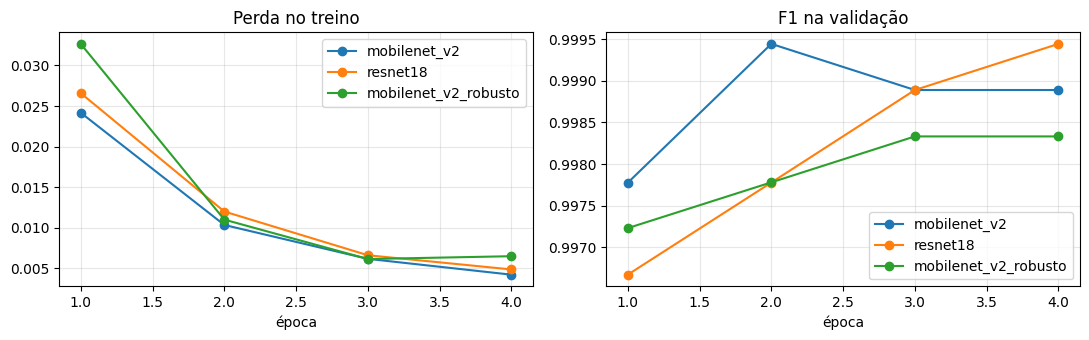

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for arch, h in historicos.items():
    ax[0].plot(h.epoca, h.perda_treino, marker='o', label=arch)
    ax[1].plot(h.epoca, h.f1_val, marker='o', label=arch)
ax[0].set_title('Perda no treino'); ax[1].set_title('F1 na validação')
for a in ax: a.set_xlabel('época'); a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.savefig(OUT / 'curvas_treino.png', dpi=110); plt.show()

### Escolha do limiar de confiança

A saída do modelo é uma probabilidade de fissura. O uso é **triagem para inspeção**: deixar passar uma
fissura (falso negativo) custa mais caro que mandar um técnico olhar uma parede sem problema (falso positivo).
Por isso o limiar é escolhido **na validação** (nunca no teste) com a regra: *maior precisão possível
mantendo recall ≥ 99%*. Se nenhum limiar atingir isso, usamos o que maximiza o F1.

In [7]:
def escolher_limiar(p, y, recall_min=0.99):
    prec, rec, thr = precision_recall_curve(y, p)
    prec, rec = prec[:-1], rec[:-1]
    ok = rec >= recall_min
    if ok.any():
        i = np.argmax(np.where(ok, prec, -1))
    else:
        f1 = 2 * prec * rec / (prec + rec + 1e-9); i = np.argmax(f1)
    return float(np.clip(thr[i], 0.05, 0.95))

limiares = {}
for arch, m in modelos.items():
    p, y = predizer(m, dl_va)
    limiares[arch] = escolher_limiar(p, y)
    print(f'{arch}: limiar escolhido na validação = {limiares[arch]:.3f}')

mobilenet_v2: limiar escolhido na validação = 0.950


resnet18: limiar escolhido na validação = 0.873


mobilenet_v2_robusto: limiar escolhido na validação = 0.950


## 3. Avaliação no conjunto de teste

In [8]:
s_te = split[split.conjunto == 'teste'].reset_index(drop=True)
resultados, probs_teste = [], {}
for arch, m in modelos.items():
    p, y = predizer(m, dl_te); probs_teste[arch] = (p, y)
    yhat = (p >= limiares[arch]).astype(int)
    resultados.append({'modelo': arch, 'limiar': limiares[arch],
                       'acuracia': accuracy_score(y, yhat), 'precisao': precision_score(y, yhat),
                       'recall': recall_score(y, yhat), 'f1': f1_score(y, yhat),
                       'auc_roc': roc_auc_score(y, p),
                       'parametros_M': sum(t.numel() for t in m.parameters()) / 1e6})
res = pd.DataFrame(resultados).set_index('modelo')
res.to_csv(OUT / 'metricas_teste.csv')
res.round(4)

,limiar,acuracia,precisao,recall,f1,auc_roc,parametros_M
modelo,,,,,,,
mobilenet_v2,0.9500,0.9989,1.0,0.9978,0.9989,1.0,2.2264
resnet18,0.8727,1.0000,1.0,1.0000,1.0000,1.0,11.1775
mobilenet_v2_robusto,0.9500,0.9956,1.0,0.9911,0.9955,1.0,2.2264


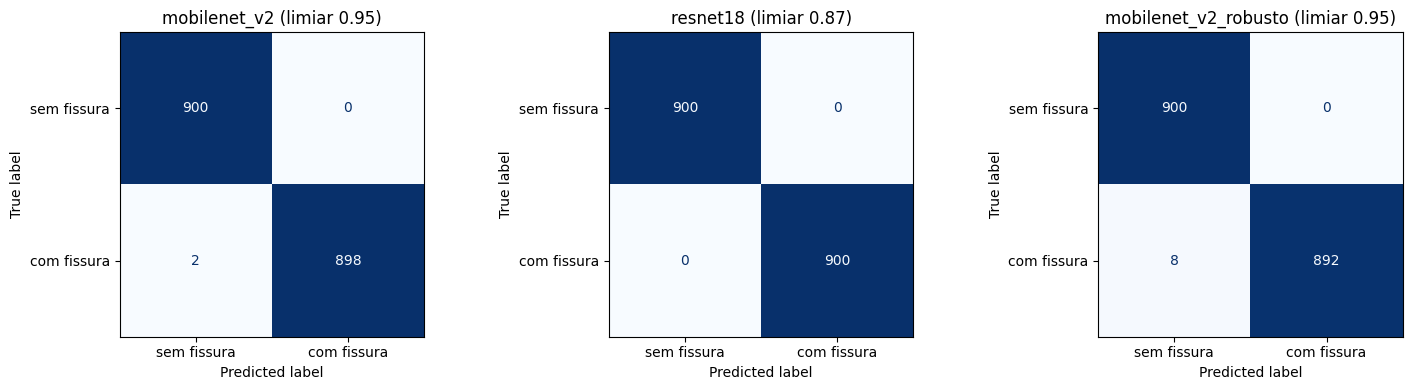

mobilenet_v2
              precision    recall  f1-score   support

 sem fissura     0.9978    1.0000    0.9989       900
 com fissura     1.0000    0.9978    0.9989       900

    accuracy                         0.9989      1800
   macro avg     0.9989    0.9989    0.9989      1800
weighted avg     0.9989    0.9989    0.9989      1800



In [9]:
fig, axes = plt.subplots(1, len(modelos), figsize=(5 * len(modelos), 4))
for ax, arch in zip(axes, modelos):
    p, y = probs_teste[arch]
    cm = confusion_matrix(y, p >= limiares[arch])
    ConfusionMatrixDisplay(cm, display_labels=['sem fissura', 'com fissura']).plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(f'{arch} (limiar {limiares[arch]:.2f})')
plt.tight_layout(); plt.savefig(OUT / 'matriz_confusao.png', dpi=110); plt.show()

p, y = probs_teste['mobilenet_v2']
print('mobilenet_v2'); print(classification_report(y, p >= limiares['mobilenet_v2'], target_names=['sem fissura', 'com fissura'], digits=4))

### Interferências: sombras, iluminação, textura, desfoque e obstáculos

Como as imagens da base são bem iluminadas e limpas, o teste original subestima o que acontece em campo.
Aplicamos ao conjunto de teste perturbações que imitam condições reais (sombra dura, pouca luz,
superexposição, desfoque de movimento, ruído de sensor, riscos/manchas que parecem fissuras e obstáculos
cobrindo parte da parede, como poste, placa ou folhagem) e medimos
de novo as métricas, **sem retreinar** e com o mesmo limiar.

> Obs.: ruído, sombra e pouca luz são parecidos com o aumento usado no treino da variante
> robusta, então para ela esses números são otimistas. Riscos/textura, obstáculos, superexposição e desfoque não foram
> usados em nenhum treino e servem de comparação justa entre os três modelos.

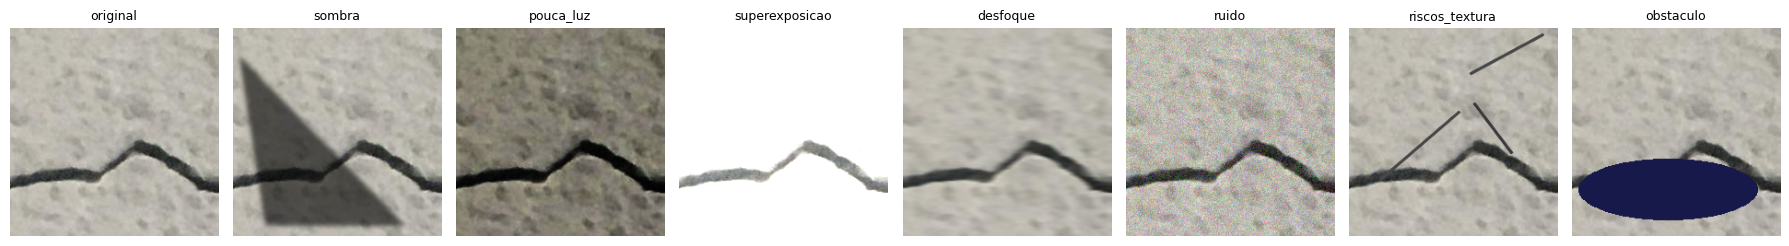

precisao                                     recall  \
modelo         mobilenet_v2 mobilenet_v2_robusto resnet18 mobilenet_v2   
condicao                                                                 
original              1.000                1.000    1.000        0.998   
sombra                0.676                1.000    0.520        1.000   
pouca_luz             0.957                1.000    1.000        0.999   
superexposicao        1.000                1.000    1.000        0.963   
desfoque              1.000                1.000    1.000        0.982   
ruido                 1.000                1.000    1.000        0.879   
riscos_textura        0.956                1.000    0.643        0.996   
obstaculo             1.000                0.943    0.796        0.959   

                                                       f1  \
modelo         mobilenet_v2_robusto resnet18 mobilenet_v2   
condicao                                                    
original                      0.991    1.000        0.999   
sombra                        0.990    1.000        0.806   
pouca_luz                     0.983    0.987        0.978   
superexposicao                0.926    0.918        0.981   
desfoque                      0.602    0.996        0.991   
ruido                         0.993    0.997        0.936   
riscos_textura                0.978    1.000        0.976   
obstaculo                     0.957    0.991        0.979   

                                              
modelo         mobilenet_v2_robusto resnet18  
condicao                                      
original                      0.996    1.000  
sombra                        0.995    0.684  
pouca_luz                     0.992    0.993  
superexposicao                0.961    0.957  
desfoque                      0.752    0.998  
ruido                         0.997    0.998  
riscos_textura                0.989    0.783  
obstaculo                     0.950    0.883

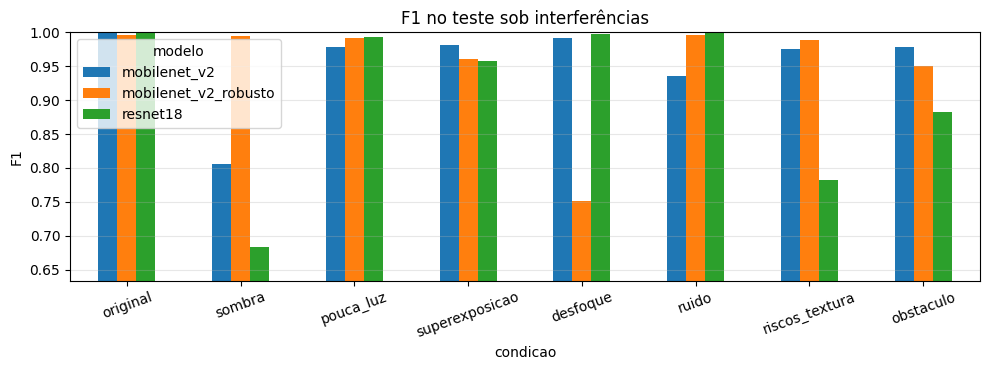

In [10]:
exemplo = np.asarray(Image.open(s_te[s_te.rotulo == 1].arquivo.iloc[3]).convert('RGB'))
rng_ex = np.random.default_rng(1)
fig, axes = plt.subplots(1, len(PERTURBACOES), figsize=(18, 2.8))
for ax, (nome, fn) in zip(axes, PERTURBACOES.items()):
    ax.imshow(exemplo if fn is None else fn(exemplo, rng_ex)); ax.set_title(nome, fontsize=9); ax.axis('off')
plt.tight_layout(); plt.savefig(OUT / 'perturbacoes_exemplo.png', dpi=110); plt.show()

rob = []
for nome, fn in PERTURBACOES.items():
    dl = loader('teste', test_tf, perturb=fn)
    for arch, m in modelos.items():
        p, y = predizer(m, dl); yhat = p >= limiares[arch]
        rob.append({'condicao': nome, 'modelo': arch, 'precisao': precision_score(y, yhat, zero_division=0),
                    'recall': recall_score(y, yhat), 'f1': f1_score(y, yhat)})
rob = pd.DataFrame(rob); rob.to_csv(OUT / 'robustez.csv', index=False)
pv = rob.pivot(index='condicao', columns='modelo', values=['precisao', 'recall', 'f1']).loc[list(PERTURBACOES)]
display(pv.round(3))

ax = rob.pivot(index='condicao', columns='modelo', values='f1').loc[list(PERTURBACOES)].plot.bar(figsize=(10, 3.8), rot=20)
ax.set_ylim(max(0, rob.f1.min() - 0.05), 1.0); ax.set_ylabel('F1'); ax.set_title('F1 no teste sob interferências'); ax.grid(axis='y', alpha=.3)
plt.tight_layout(); plt.savefig(OUT / 'robustez_f1.png', dpi=110); plt.show()

## 5. Desempenho: latência e FPS

Medimos a latência de uma imagem por vez (cenário do app: o cidadão ou fiscal envia uma foto) e a vazão
em lote (cenário de monitoramento, vários quadros de uma vez). Entrada 224×224, já incluindo o pré-processamento
com OpenCV. Descartamos as primeiras execuções (aquecimento) e sincronizamos a GPU antes de parar o relógio.

In [11]:
from detector import _to_tensor_batch
imgs_bench = [np.asarray(Image.open(f).convert('RGB')) for f in s_te.arquivo.sample(64, random_state=SEED)]

def medir(m, dev, bs, rep):
    m = m.to(dev).eval(); ts = []
    with torch.inference_mode():
        for i in range(rep + 5):
            lote = [imgs_bench[(i * bs + k) % len(imgs_bench)] for k in range(bs)]
            t0 = time.perf_counter()
            x = _to_tensor_batch(lote).to(dev)
            torch.softmax(m(x), 1)
            if dev.type == 'cuda': torch.cuda.synchronize()
            if i >= 5: ts.append(time.perf_counter() - t0)
    ts = np.array(ts)
    return ts.mean() * 1000 / bs, bs / ts.mean()

bench = []
modelos_bench = {k: v for k, v in modelos.items() if k != 'mobilenet_v2_robusto'}
devs = [torch.device('cuda'), torch.device('cpu')] if device.type == 'cuda' else [torch.device('cpu')]
for arch, m in modelos_bench.items():
    for dev in devs:
        for bs, rep in [(1, 100 if dev.type == 'cuda' else 40), (32, 20 if dev.type == 'cuda' else 5)]:
            ms, fps = medir(m, dev, bs, rep)
            bench.append({'modelo': arch, 'equipamento': GPU if dev.type == 'cuda' else 'CPU: ' + platform.processor(),
                          'lote': bs, 'latencia_ms_por_imagem': ms, 'imagens_por_segundo': fps})
    m.to(device)
bench = pd.DataFrame(bench); bench.to_csv(OUT / 'desempenho.csv', index=False)
bench.round(2)

,modelo,equipamento,lote,latencia_ms_por_imagem,imagens_por_segundo
0,mobilenet_v2,NVIDIA GeForce GTX 1660 SUPER,1,8.20,122.02
1,mobilenet_v2,NVIDIA GeForce GTX 1660 SUPER,32,1.84,542.60
2,mobilenet_v2,"CPU: Intel64 Family 6 Model 165 Stepping 5, Ge...",1,14.12,70.82
3,mobilenet_v2,"CPU: Intel64 Family 6 Model 165 Stepping 5, Ge...",32,16.75,59.69
4,resnet18,NVIDIA GeForce GTX 1660 SUPER,1,5.33,187.46
5,resnet18,NVIDIA GeForce GTX 1660 SUPER,32,2.20,455.32
6,resnet18,"CPU: Intel64 Family 6 Model 165 Stepping 5, Ge...",1,28.90,34.60
7,resnet18,"CPU: Intel64 Family 6 Model 165 Stepping 5, Ge...",32,14.42,69.33


### Salvando o modelo escolhido

Regra de escolha: entre os modelos com F1 no teste limpo a no máximo 0,005 do melhor (empate técnico),
preferimos uma MobileNetV2 (mais leve) e, entre elas, a de maior F1 médio sob interferências.

In [12]:
f1_interf = rob.groupby('modelo').f1.mean().rename('f1_medio_interferencias')
display(res[['f1']].join(f1_interf).round(4))
empate = res.index[res.f1 >= res.f1.max() - 0.005]
leves = [m for m in empate if ARCH[m] == 'mobilenet_v2']
escolhido = max(leves, key=lambda m: f1_interf[m]) if leves else res.f1.idxmax()
print('Modelo escolhido para o protótipo:', escolhido)
torch.save(modelos[escolhido].state_dict(), MODELS / 'mobilenet_v2_fissuras.pt')
meta = {'arch': ARCH[escolhido], 'variante': escolhido, 'weights': 'mobilenet_v2_fissuras.pt', 'threshold': limiares[escolhido],
        'img_size': IMG_SIZE, 'classes': ['sem_fissura', 'com_fissura'],
        'metricas_teste': res.loc[escolhido].to_dict(),
        'f1_medio_interferencias': float(f1_interf[escolhido]),
        'treinado_em': GPU, 'data': time.strftime('%Y-%m-%d'),
        'base': 'Concrete Crack Images for Classification (Ozgenel, 2018)'}
(MODELS / 'model_meta.json').write_text(json.dumps(meta, indent=2, ensure_ascii=False), encoding='utf-8')
print(json.dumps(meta, indent=2, ensure_ascii=False))

,f1,f1_medio_interferencias
modelo,,
mobilenet_v2,0.9989,0.9557
resnet18,1.0000,0.9120
mobilenet_v2_robusto,0.9955,0.9538


Modelo escolhido para o protótipo: mobilenet_v2
{
  "arch": "mobilenet_v2",
  "variante": "mobilenet_v2",
  "weights": "mobilenet_v2_fissuras.pt",
  "threshold": 0.949999988079071,
  "img_size": 224,
  "classes": [
    "sem_fissura",
    "com_fissura"
  ],
  "metricas_teste": {
    "limiar": 0.949999988079071,
    "acuracia": 0.9988888888888889,
    "precisao": 1.0,
    "recall": 0.9977777777777778,
    "f1": 0.9988876529477196,
    "auc_roc": 0.9999987654320988,
    "parametros_M": 2.226434
  },
  "f1_medio_interferencias": 0.955682236661542,
  "treinado_em": "NVIDIA GeForce GTX 1660 SUPER",
  "data": "2026-11-14",
  "base": "Concrete Crack Images for Classification (Ozgenel, 2018)"
}


### Acertos e erros

Mostramos todos os erros do modelo escolhido para o app no teste (até 12). Como a base é limpa, os erros são poucos;
por isso mostramos também os acertos **mais difíceis**, com probabilidade mais perto do limiar.

Erros no teste: 2 de 1800  (FP=0, FN=2)


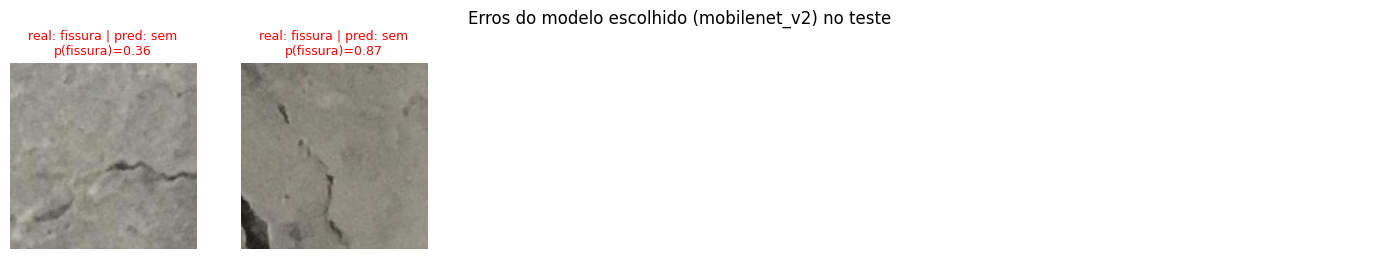

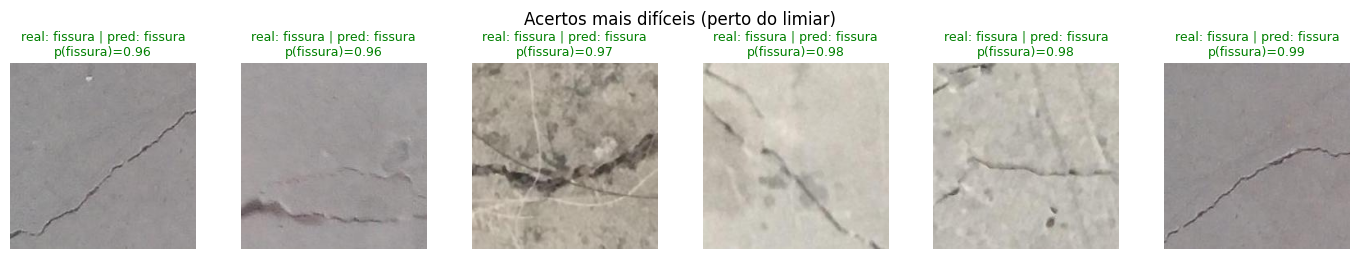

In [13]:
p, y = probs_teste[escolhido]; thr = limiares[escolhido]
s_te['prob'] = p; s_te['pred'] = (p >= thr).astype(int)
erros = s_te[s_te.pred != s_te.rotulo]
acertos = s_te[s_te.pred == s_te.rotulo].assign(margem=lambda d: (d.prob - thr).abs()).nsmallest(6, 'margem')
print(f'Erros no teste: {len(erros)} de {len(s_te)}  (FP={((s_te.pred==1)&(s_te.rotulo==0)).sum()}, FN={((s_te.pred==0)&(s_te.rotulo==1)).sum()})')

def grade(df_, titulo, arquivo, n=12):
    df_ = df_.head(n)
    if df_.empty:
        print('nenhuma imagem para mostrar em', titulo); return
    cols = 6; rows = int(np.ceil(len(df_) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(14, 2.6 * rows), squeeze=False)
    for ax in axes.flat: ax.axis('off')
    for ax, (_, r) in zip(axes.flat, df_.iterrows()):
        ax.imshow(Image.open(r.arquivo))
        real = 'fissura' if r.rotulo else 'sem'; pred = 'fissura' if r.pred else 'sem'
        ax.set_title(f'real: {real} | pred: {pred}\np(fissura)={r.prob:.2f}', fontsize=9,
                     color='green' if r.rotulo == r.pred else 'red')
    plt.suptitle(titulo); plt.tight_layout(); plt.savefig(OUT / arquivo, dpi=110); plt.show()

grade(erros, f'Erros do modelo escolhido ({escolhido}) no teste', 'erros_teste.png')
grade(acertos, 'Acertos mais difíceis (perto do limiar)', 'acertos_dificeis.png')

## 4. Processamento de vídeo: simulação de monitoramento urbano

Para simular uma câmera percorrendo uma parede (veículo, drone ou fiscal com celular), montamos um
"muro" com recortes **do conjunto de teste** (o modelo nunca viu essas imagens) e geramos um vídeo com a
câmera deslizando sobre ele. Cada quadro de 908×680 px é varrido em blocos de 227×227 (12 blocos por quadro),
cada bloco é classificado, e os blocos com fissura são destacados em vermelho com a confiança. Os blocos da
varredura não ficam alinhados com os recortes do muro durante o movimento, o que deixa o teste mais realista.

In [14]:
demo_dir = DATA / 'demo'; demo_dir.mkdir(exist_ok=True)
rng_v = np.random.default_rng(7)
neg = s_te[s_te.rotulo == 0].arquivo.tolist(); pos = s_te[s_te.rotulo == 1].arquivo.tolist()
LIN, COL, T = 4, 18, 227
muro = np.zeros((LIN * T, COL * T, 3), np.uint8)
mapa_real = np.zeros((LIN, COL), int)
for r in range(LIN):
    for c in range(COL):
        tem = rng_v.random() < (0.6 if 5 <= c <= 6 or 11 <= c <= 12 else 0.0)
        f = rng_v.choice(pos if tem else neg); mapa_real[r, c] = tem
        muro[r*T:(r+1)*T, c*T:(c+1)*T] = cv2.resize(np.asarray(Image.open(f).convert('RGB')), (T, T))
cv2.imwrite(str(demo_dir / 'muro_demo.jpg'), cv2.cvtColor(muro, cv2.COLOR_RGB2BGR))

FW, FH = 4 * T, 3 * T
video_in = demo_dir / 'inspecao_demo.mp4'
vw = cv2.VideoWriter(str(video_in), cv2.VideoWriter_fourcc(*'mp4v'), 15, (FW, FH))
n_q = 0
for x in range(0, muro.shape[1] - FW + 1, 12):
    y = int((muro.shape[0] - FH) * (0.5 + 0.5 * np.sin(x / 300)))
    vw.write(cv2.cvtColor(muro[y:y+FH, x:x+FW], cv2.COLOR_RGB2BGR)); n_q += 1
vw.release()
print('Vídeo de entrada:', video_in, '|', n_q, 'quadros', f'{FW}x{FH}')

seq_dir = demo_dir / 'sequencia'; seq_dir.mkdir(exist_ok=True)
for i, x in enumerate(range(0, muro.shape[1] - FW + 1, 227)):
    cv2.imwrite(str(seq_dir / f'quadro_{i:02d}.jpg'), cv2.cvtColor(muro[0:FH, x:x+FW], cv2.COLOR_RGB2BGR))

Vídeo de entrada: C:\Users\ramos\GS_VC_ManutencaoUrbana\data\demo\inspecao_demo.mp4 | 265 quadros 908x681


{
  "quadros": 265,
  "resolucao": "908x680",
  "latencia_media_ms": 24.463685605841228,
  "fps": 40.87691511867814,
  "quadros_com_alerta": 194,
  "equipamento": "NVIDIA GeForce GTX 1660 SUPER"
}


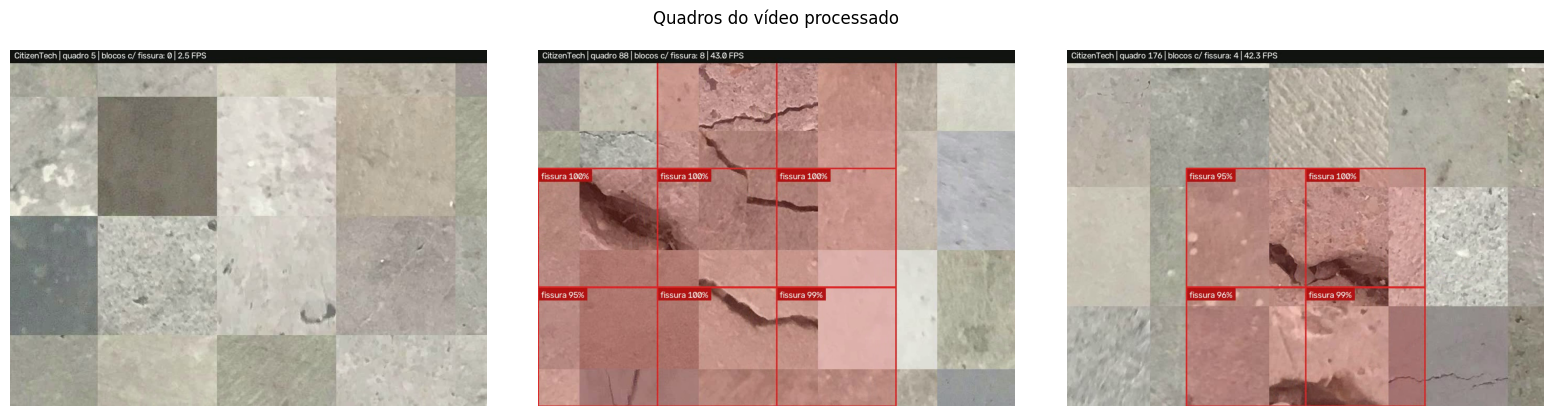

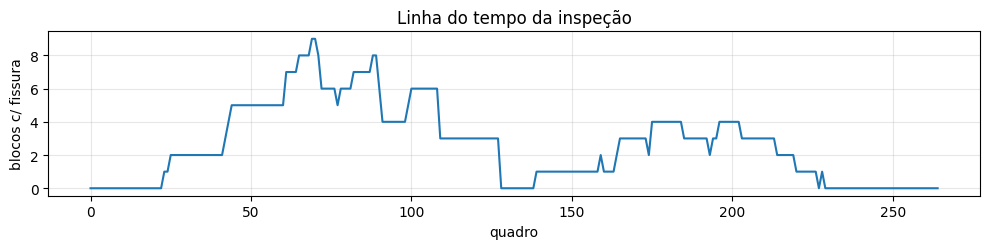

In [15]:
det = CrackDetector(MODELS)
video_out = OUT / 'inspecao_processada.mp4'
stats = det.process_video(video_in, video_out)
tl = pd.DataFrame(stats.pop('timeline'))
stats['equipamento'] = GPU
(OUT / 'desempenho_video.json').write_text(json.dumps(stats, indent=2, ensure_ascii=False), encoding='utf-8')
print(json.dumps(stats, indent=2, ensure_ascii=False))

cap = cv2.VideoCapture(str(video_out)); quadros = []
for idx in [5, n_q // 3, 2 * n_q // 3]:
    cap.set(cv2.CAP_PROP_POS_FRAMES, idx); ok, f = cap.read(); quadros.append(cv2.cvtColor(f, cv2.COLOR_BGR2RGB))
cap.release()
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, q in zip(axes, quadros): ax.imshow(q); ax.axis('off')
plt.suptitle('Quadros do vídeo processado'); plt.tight_layout(); plt.savefig(OUT / 'quadros_video.png', dpi=110); plt.show()

ax = tl.plot(x='quadro', y='blocos_com_fissura', figsize=(10, 2.6), legend=False)
ax.set_ylabel('blocos c/ fissura'); ax.set_title('Linha do tempo da inspeção'); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(OUT / 'linha_tempo_video.png', dpi=110); plt.show()

## Conclusões e justificativa técnica

**Arquitetura.** As duas CNNs pré-treinadas chegam a métricas muito altas nesta base (tabela de teste acima).
Com qualidade praticamente empatada, o critério de desempate é velocidade e custo de implantação: a
MobileNetV2 tem cerca de 5 vezes menos parâmetros que a ResNet18 e é a rede pensada para rodar em celular e
em equipamento simples, que é o que uma prefeitura tem. Treinar do zero não faria sentido no prazo e com
uma amostra: a transferência de aprendizado aproveita filtros de borda e textura já aprendidos na ImageNet,
que é o que importa para achar uma fissura.

**Pré-processamento.** Redimensionar para 224 px custa quase nada (as imagens têm 227 px) e permite usar os
pesos pré-treinados sem adaptação. A normalização da ImageNet é obrigatória para esses pesos. O aumento de
dados com rotação/espelhamento e brilho/contraste melhora a tolerância a fotos tiradas em qualquer ângulo e luz.

**Limiar.** Escolhido na validação priorizando recall ≥ 99%, porque o sistema faz triagem: um falso alarme
custa uma visita de técnico, mas uma fissura perdida pode virar um problema maior. O fiscal sempre confirma o
resultado no app.

**Velocidade e qualidade.** Na GTX 1660 Super a latência por imagem fica na casa de poucos milissegundos, e
o vídeo com 12 blocos por quadro roda acima do tempo real (ver tabela de desempenho e `desempenho_video.json`).
Mesmo em CPU o modelo atende o uso no app, em que o cidadão envia uma foto por vez.

**Limitações.**
* A base tem fotos de um único campus, bem iluminadas e com fissuras visíveis; o teste de interferências
  mostra onde o desempenho cai (veja a tabela de robustez) e indica que, antes de usar em campo, é preciso
  coletar fotos locais (inclusive com sombra e sujeira) e retreinar.
* A divisão por blocos de arquivos consecutivos reduz, mas não garante 100%, a separação por foto original,
  porque a base não informa essa origem.
* O modelo indica **presença** de fissura, não **gravidade** nem risco estrutural. A decisão sobre a segurança
  da edificação é sempre de um engenheiro.